# Exploratory Data Analysis (EDA): Global Instagram Influencers (2026)

## Overview
This notebook performs a comprehensive **Exploratory Data Analysis (EDA)** on the **`instagram_global_influencers_2026.csv`** dataset, which tracks the top 100 global Instagram accounts across key metrics including rank, influence score, post volume, follower count, average likes, 60-day engagement rate, country, and content category.

### Objectives
1. **Understand Data Structure & Quality:** Inspect dimensions, data types, missing values, and duplicates.
2. **Statistical Profiling & Feature Engineering:** Compute summary statistics and derive analytical features (e.g., primary category, like momentum ratio, follower tiers).
3. **Univariate Analysis:** Explore distributions of numerical metrics and frequency breakdowns across countries and categories.
4. **Top Performers & Rankings:** Compare top accounts by reach (`followers`) versus engagement (`60_day_eng_rate`).
5. **Bivariate & Multivariate Analysis:** Examine correlations, scaling effects (followers vs. engagement rate), and group-level trends.
6. **Outlier Detection:** Identify statistical anomalies using IQR and boxplots.

## 1. Import Libraries & Load Dataset

In [8]:
pip install matplotlib seaborn


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [9]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

# Set consistent visual styling
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams['figure.figsize'] = (11, 6)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'

# Load the dataset
df = pd.read_csv('instagram_global_influencers_2026.csv')

print(f"Dataset loaded successfully! Shape: {df.shape[0]} rows x {df.shape[1]} columns")
df.head(10)

Dataset loaded successfully! Shape: 100 rows x 11 columns


,rank,channel_info,influence_score,posts,followers,avg_likes,60_day_eng_rate,new_post_avg_likes,total_likes,country,category
0,1,cristiano,98,3782,680000000,12800000,1.89,14200000,48400000000,Portugal,Sports
1,2,leomessi,97,1204,517000000,14300000,2.77,16100000,17200000000,Argentina,Sports
2,3,selenagomez,96,1935,403000000,8700000,2.16,9400000,16800000000,United States,Music/Entertainment
3,4,therock,95,7842,381000000,4200000,1.10,4800000,32900000000,United States,Entertainment/Fitness
4,5,kyliejenner,94,7216,380000000,7500000,1.97,8100000,54100000000,United States,Fashion/Business
5,6,arianagrande,93,5124,362000000,5100000,1.41,5600000,26100000000,United States,Music
6,7,kimkardashian,92,6148,344000000,5800000,1.68,6200000,35600000000,United States,Fashion/Media
7,8,beyonce,91,2374,299000000,6900000,2.31,7500000,16400000000,United States,Music
8,9,khloekardashian,89,4127,291000000,3900000,1.34,4200000,16100000000,United States,Media/Fashion
9,10,nike,88,1247,291000000,1200000,0.41,1400000,1500000000,United States,Sportswear Brand


## 2. Data Structure & Quality Assessment
Let's inspect column names, data types, missing values, duplicate rows, and cardinality (unique values per column).

In [10]:
# Dataset info and data types
print("--- Data Types & Non-Null Counts ---")
df.info()

print("\n--- Missing Values per Column ---")
print(df.isnull().sum())

print(f"\n--- Duplicate Rows ---\nTotal duplicate rows: {df.duplicated().sum()}")

print("\n--- Unique Values per Column ---")
print(df.nunique())

--- Data Types & Non-Null Counts ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   rank                100 non-null    int64  
 1   channel_info        100 non-null    object 
 2   influence_score     100 non-null    int64  
 3   posts               100 non-null    int64  
 4   followers           100 non-null    int64  
 5   avg_likes           100 non-null    int64  
 6   60_day_eng_rate     100 non-null    float64
 7   new_post_avg_likes  100 non-null    int64  
 8   total_likes         100 non-null    int64  
 9   country             100 non-null    object 
 10  category            100 non-null    object 
dtypes: float64(1), int64(7), object(3)
memory usage: 8.7+ KB

--- Missing Values per Column ---
rank                  0
channel_info          0
influence_score       0
posts                 0
followers             0
avg_l

## 3. Summary Statistics & Feature Engineering
We inspect descriptive statistics for numerical and categorical columns, and engineer clean helper columns (such as millions-scaled metrics, primary category, and recent like momentum) to make charts and comparisons easier to interpret.

In [11]:
# Summary statistics for numerical features
display_cols = ['influence_score', 'posts', 'followers', 'avg_likes',
                '60_day_eng_rate', 'new_post_avg_likes', 'total_likes']
print("--- Numerical Summary Statistics ---")
print(df[display_cols].describe().round(2).to_string())

print("\n--- Categorical Summary Statistics ---")
print(df[['channel_info', 'country', 'category']].describe().to_string())

# Feature Engineering for cleaner analysis & visualization
df['followers_M'] = df['followers'] / 1e6
df['avg_likes_M'] = df['avg_likes'] / 1e6
df['new_post_avg_likes_M'] = df['new_post_avg_likes'] / 1e6
df['total_likes_B'] = df['total_likes'] / 1e9
df['primary_category'] = df['category'].apply(lambda x: x.split('/')[0].strip())
df['like_momentum_ratio'] = (df['new_post_avg_likes'] / df['avg_likes']).round(3)

print("\nEngineered columns added: followers_M, avg_likes_M, new_post_avg_likes_M, total_likes_B, primary_category, like_momentum_ratio")

--- Numerical Summary Statistics ---
       influence_score     posts     followers    avg_likes  60_day_eng_rate  new_post_avg_likes   total_likes
count           100.00    100.00  1.000000e+02       100.00           100.00              100.00  1.000000e+02
mean             63.54   6215.38  1.257040e+08   2820400.00             2.96          3084600.00  9.503970e+09
std              17.79  11524.37  1.176260e+08   2562349.35             2.42          2808253.86  1.070980e+10
min              30.00    318.00  4.800000e+06    180000.00             0.30           210000.00  1.430000e+08
25%              50.00   1178.50  5.300000e+07    877500.00             1.27           955000.00  2.357500e+09
50%              63.00   2846.50  7.980000e+07   2100000.00             2.08          2300000.00  4.895000e+09
75%              77.00   5400.25  1.557500e+08   4200000.00             4.16          4600000.00  1.225000e+10
max              98.00  82416.00  6.800000e+08  14300000.00            11.9

## 4. Univariate Analysis
### 4.1 Distribution of Key Numerical Metrics

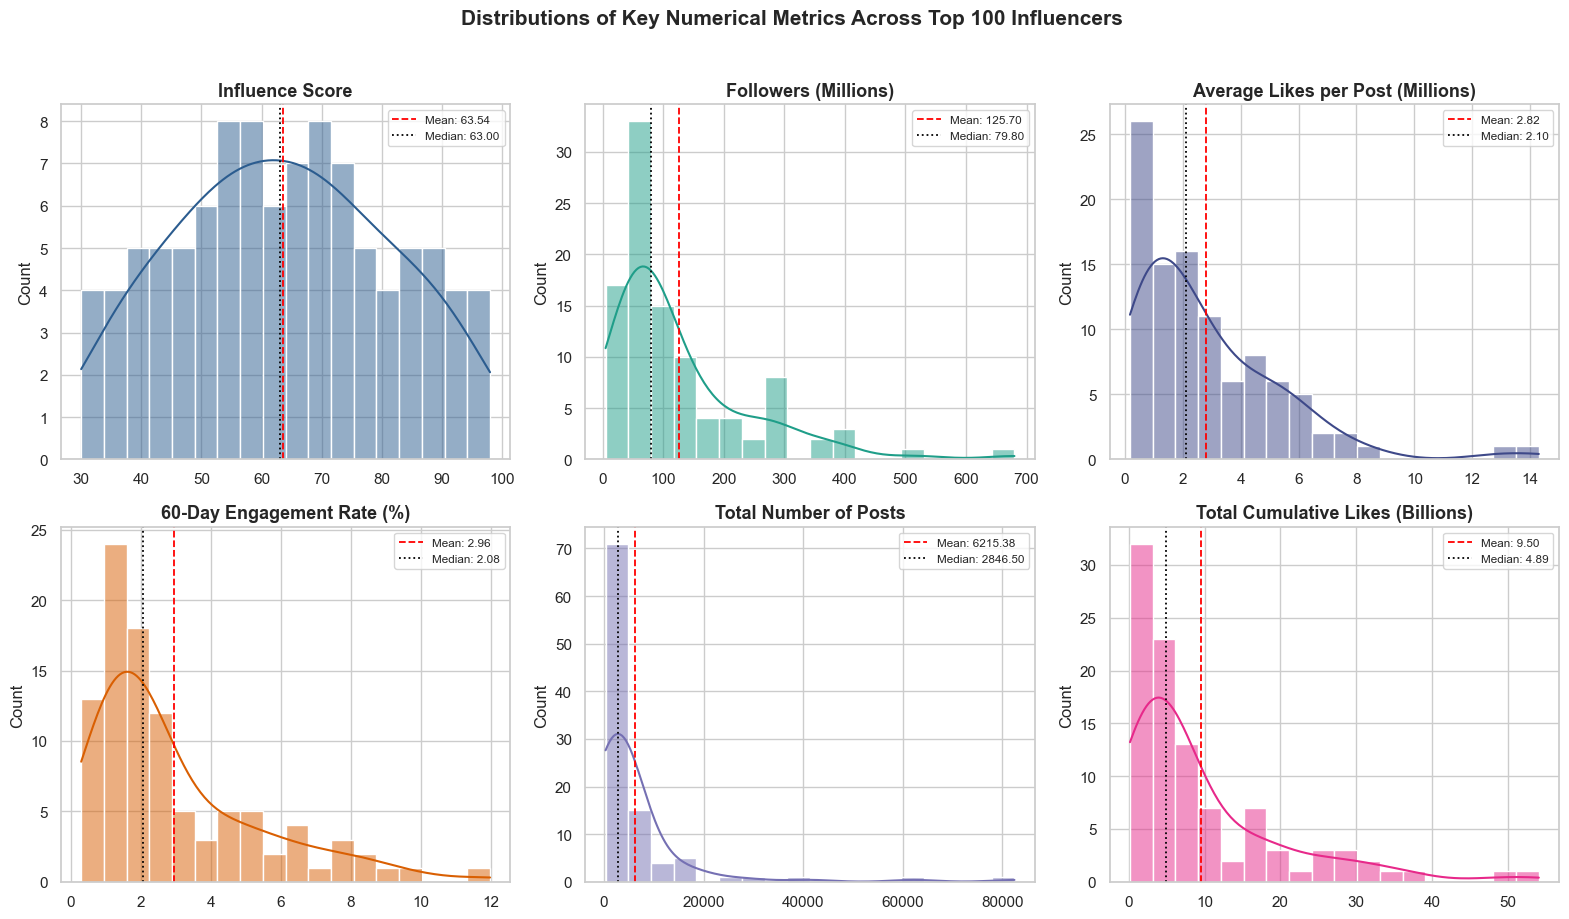

In [12]:
num_features = [
    ('influence_score', 'Influence Score', '#2b5c8f'),
    ('followers_M', 'Followers (Millions)', '#1f9e89'),
    ('avg_likes_M', 'Average Likes per Post (Millions)', '#3e4989'),
    ('60_day_eng_rate', '60-Day Engagement Rate (%)', '#d95f02'),
    ('posts', 'Total Number of Posts', '#7570b3'),
    ('total_likes_B', 'Total Cumulative Likes (Billions)', '#e7298a')
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for idx, (col, title, color) in enumerate(num_features):
    sns.histplot(df[col], kde=True, ax=axes[idx], color=color, bins=18, edgecolor='white')
    mean_val = df[col].mean()
    med_val = df[col].median()
    axes[idx].axvline(mean_val, color='red', linestyle='--', linewidth=1.3, label=f'Mean: {mean_val:.2f}')
    axes[idx].axvline(med_val, color='black', linestyle=':', linewidth=1.3, label=f'Median: {med_val:.2f}')
    axes[idx].set_title(title)
    axes[idx].set_xlabel('')
    axes[idx].legend(fontsize=8.5)

plt.suptitle('Distributions of Key Numerical Metrics Across Top 100 Influencers', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Followers vs Average Likes
scatter1 = axes[0].scatter(df['followers_M'], df['avg_likes_M'],
                           c=df['influence_score'], cmap='viridis',
                           s=75, alpha=0.85, edgecolors='k', linewidth=0.5)
sns.regplot(data=df, x='followers_M', y='avg_likes_M', scatter=False, ax=axes[0],
            color='crimson', label='Linear Trend', line_kws={'linestyle': '--'})
cbar1 = plt.colorbar(scatter1, ax=axes[0])
cbar1.set_label('Influence Score')
axes[0].set_title('Followers vs. Average Likes (Colored by Influence Score)')
axes[0].set_xlabel('Followers (Millions)')
axes[0].set_ylabel('Average Likes per Post (Millions)')
axes[0].legend(loc='upper left')

# Plot 2: Followers vs 60-Day Engagement Rate
scatter2 = axes[1].scatter(df['followers_M'], df['60_day_eng_rate'],
                           c=df['avg_likes_M'], cmap='plasma',
                           s=75, alpha=0.85, edgecolors='k', linewidth=0.5)
sns.regplot(data=df, x='followers_M', y='60_day_eng_rate', scatter=False, ax=axes[1],
            color='navy', label='Linear Trend', line_kws={'linestyle': '--'})
cbar2 = plt.colorbar(scatter2, ax=axes[1])
cbar2.set_label('Average Likes (Millions)')
axes[1].set_title('Followers vs. 60-Day Engagement Rate (%)')
axes[1].set_xlabel('Followers (Millions)')
axes[1].set_ylabel('60-Day Engagement Rate (%)')
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()

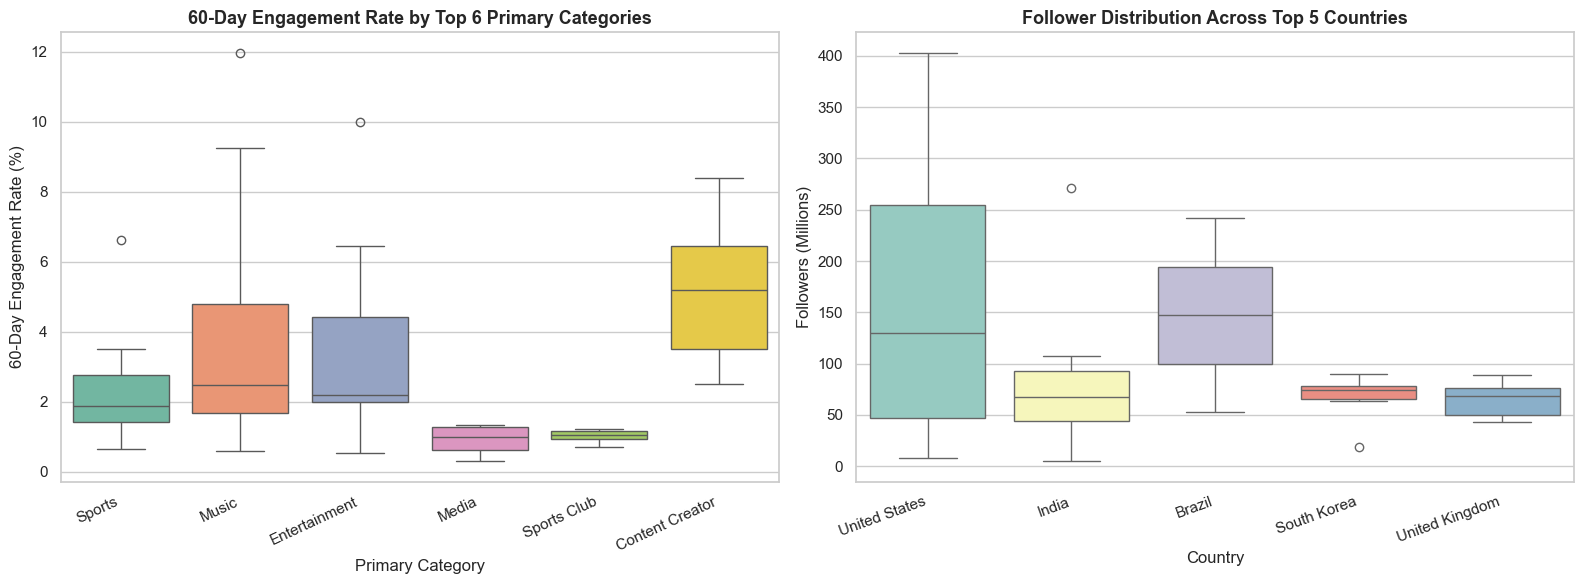

--- Performance Summary by Top Primary Categories ---
                     accounts  avg_followers_M  avg_likes_M  median_eng_rate
primary_category                                                            
Music                      34           135.38         3.52             2.47
Entertainment              15           103.32         2.83             2.18
Sports                     13           182.50         3.96             1.89
Content Creator             9            44.41         2.32             5.19
Sports Club                 5           101.28         1.10             1.05
Media                       4           198.30         1.88             0.99
Modeling                    2           178.70         3.75             2.29
Sports Organization         2            89.60         0.80             0.94


In [13]:
# Filter to top 6 primary categories and top 5 countries for clean group comparisons
top6_cats = df['primary_category'].value_counts().head(6).index
top5_countries = df['country'].value_counts().head(5).index

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(data=df[df['primary_category'].isin(top6_cats)],
            x='primary_category', y='60_day_eng_rate', ax=axes[0], palette='Set2')
axes[0].set_title('60-Day Engagement Rate by Top 6 Primary Categories')
axes[0].set_xlabel('Primary Category')
axes[0].set_ylabel('60-Day Engagement Rate (%)')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=25, ha='right')

sns.boxplot(data=df[df['country'].isin(top5_countries)],
            x='country', y='followers_M', ax=axes[1], palette='Set3')
axes[1].set_title('Follower Distribution Across Top 5 Countries')
axes[1].set_xlabel('Country')
axes[1].set_ylabel('Followers (Millions)')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=20, ha='right')

plt.tight_layout()
plt.show()

# Aggregated summary table by primary category
cat_summary = (df.groupby('primary_category')
                 .agg(accounts=('channel_info', 'count'),
                      avg_followers_M=('followers_M', 'mean'),
                      avg_likes_M=('avg_likes_M', 'mean'),
                      median_eng_rate=('60_day_eng_rate', 'median'))
                 .sort_values(by='accounts', ascending=False)
                 .head(8)
                 .round(2))
print("--- Performance Summary by Top Primary Categories ---")
print(cat_summary.to_string())

## 5. Top Performers & Rankings Analysis
Does having the highest follower count translate to the highest engagement rate? Let's compare the **Top 10 by Followers** against the **Top 10 by 60-Day Engagement Rate**.

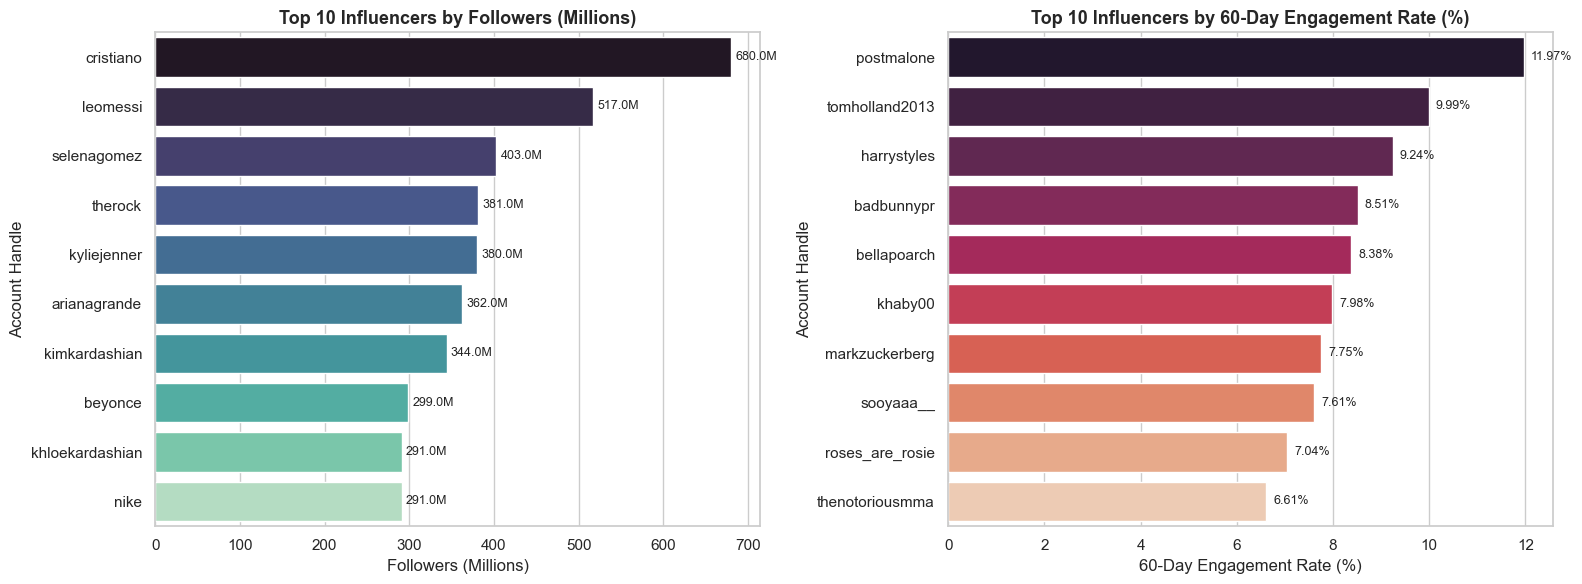

Top 5 Influencers by Recent Like Momentum (new_post_avg_likes / avg_likes):
 rank channel_info              category  avg_likes_M  new_post_avg_likes_M  like_momentum_ratio
   94        oprah              Media/TV         0.18                  0.21                1.167
   10         nike      Sportswear Brand         1.20                  1.40                1.167
   15       natgeo     Media/Photography         0.82                  0.94                1.146
    4      therock Entertainment/Fitness         4.20                  4.80                1.143
   22   realmadrid           Sports Club         2.10                  2.40                1.143


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Top 10 by Followers
top_followers = df.nlargest(10, 'followers_M')
sns.barplot(data=top_followers, x='followers_M', y='channel_info', ax=axes[0], palette='mako')
axes[0].set_title('Top 10 Influencers by Followers (Millions)')
axes[0].set_xlabel('Followers (Millions)')
axes[0].set_ylabel('Account Handle')
for i, v in enumerate(top_followers['followers_M']):
    axes[0].text(v + 5, i, f"{v:.1f}M", va='center', fontsize=9)

# Top 10 by 60-Day Engagement Rate
top_eng = df.nlargest(10, '60_day_eng_rate')
sns.barplot(data=top_eng, x='60_day_eng_rate', y='channel_info', ax=axes[1], palette='rocket')
axes[1].set_title('Top 10 Influencers by 60-Day Engagement Rate (%)')
axes[1].set_xlabel('60-Day Engagement Rate (%)')
axes[1].set_ylabel('Account Handle')
for i, v in enumerate(top_eng['60_day_eng_rate']):
    axes[1].text(v + 0.15, i, f"{v:.2f}%", va='center', fontsize=9)

plt.tight_layout()
plt.show()

print("Top 5 Influencers by Recent Like Momentum (new_post_avg_likes / avg_likes):")
print(df[['rank', 'channel_info', 'category', 'avg_likes_M', 'new_post_avg_likes_M', 'like_momentum_ratio']]
      .sort_values(by='like_momentum_ratio', ascending=False).head(5).to_string(index=False))

## 6. Bivariate & Multivariate Analysis
### 6.1 Correlation Matrix Heatmap

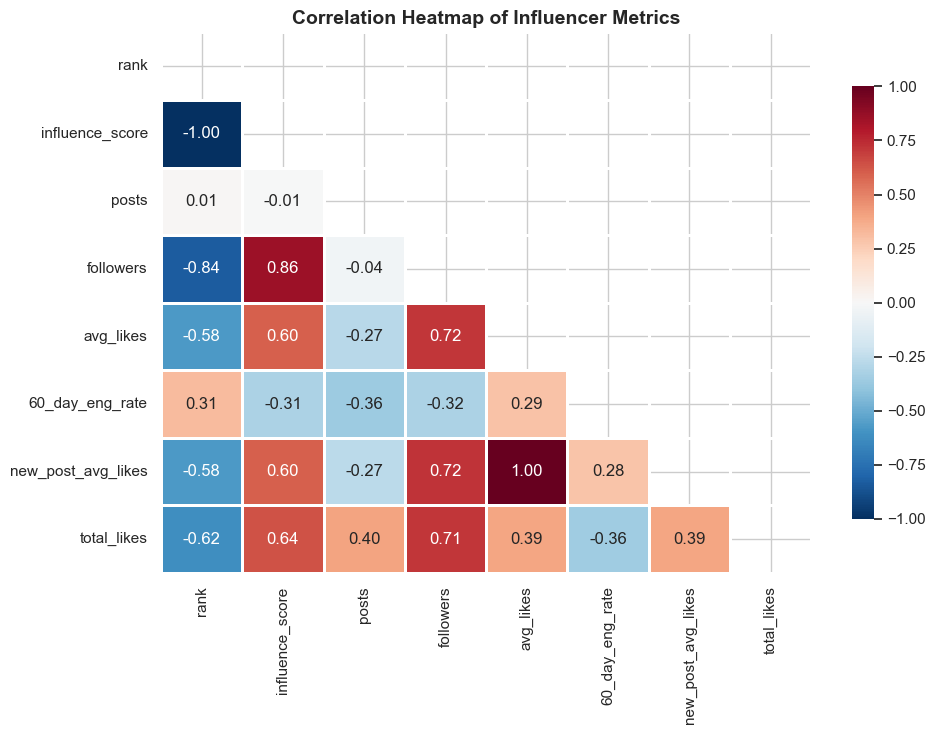

In [15]:
corr_cols = ['rank', 'influence_score', 'posts', 'followers', 'avg_likes',
             '60_day_eng_rate', 'new_post_avg_likes', 'total_likes']
corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(10, 7.5))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            vmin=-1, vmax=1, center=0, linewidths=0.8, cbar_kws={'shrink': 0.8})
plt.title('Correlation Heatmap of Influencer Metrics', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 6.2 Reach vs. Engagement Dynamics (Scatter & Regression Analysis)

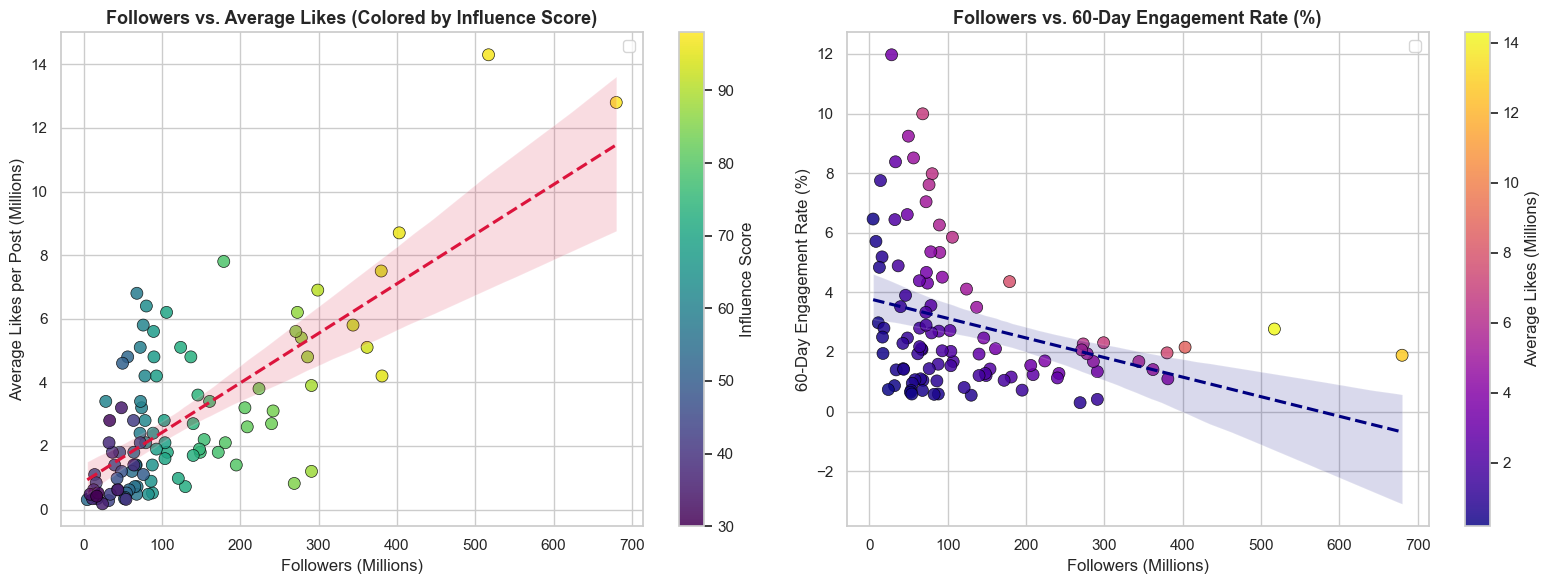

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Followers vs Average Likes
scatter1 = axes[0].scatter(df['followers_M'], df['avg_likes_M'],
                           c=df['influence_score'], cmap='viridis',
                           s=75, alpha=0.85, edgecolors='k', linewidth=0.5)
sns.regplot(data=df, x='followers_M', y='avg_likes_M', scatter=False, ax=axes[0],
            color='crimson', line_kws={'linestyle': '--', 'label': 'Linear Trend'})
cbar1 = plt.colorbar(scatter1, ax=axes[0])
cbar1.set_label('Influence Score')
axes[0].set_title('Followers vs. Average Likes (Colored by Influence Score)')
axes[0].set_xlabel('Followers (Millions)')
axes[0].set_ylabel('Average Likes per Post (Millions)')
axes[0].legend()

# Plot 2: Followers vs 60-Day Engagement Rate
scatter2 = axes[1].scatter(df['followers_M'], df['60_day_eng_rate'],
                           c=df['avg_likes_M'], cmap='plasma',
                           s=75, alpha=0.85, edgecolors='k', linewidth=0.5)
sns.regplot(data=df, x='followers_M', y='60_day_eng_rate', scatter=False, ax=axes[1],
            color='navy', line_kws={'linestyle': '--', 'label': 'Linear Trend'})
cbar2 = plt.colorbar(scatter2, ax=axes[1])
cbar2.set_label('Average Likes (Millions)')
axes[1].set_title('Followers vs. 60-Day Engagement Rate (%)')
axes[1].set_xlabel('Followers (Millions)')
axes[1].set_ylabel('60-Day Engagement Rate (%)')
axes[1].legend()

plt.tight_layout()
plt.show()

### 6.3 Category & Country Performance Comparison

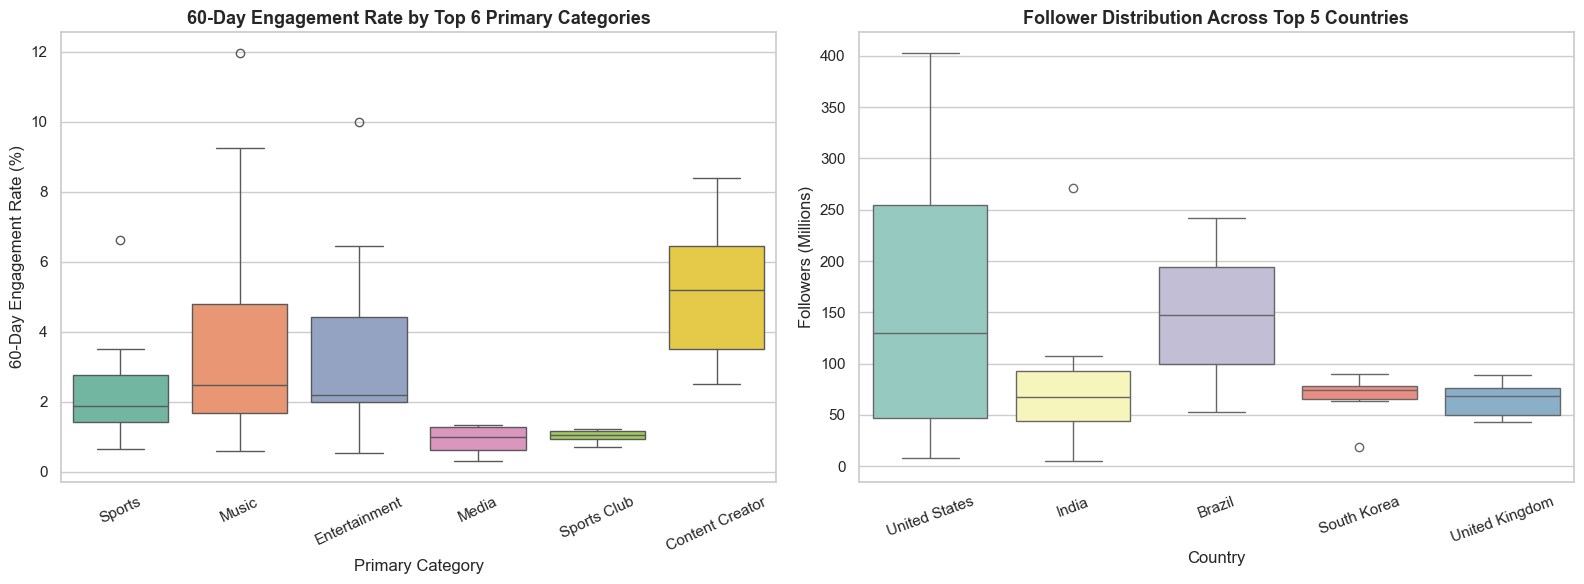

--- Performance Summary by Top Primary Categories ---
                     accounts  avg_followers_M  avg_likes_M  median_eng_rate
primary_category                                                            
Music                      34           135.38         3.52             2.47
Entertainment              15           103.32         2.83             2.18
Sports                     13           182.50         3.96             1.89
Content Creator             9            44.41         2.32             5.19
Sports Club                 5           101.28         1.10             1.05
Media                       4           198.30         1.88             0.99
Modeling                    2           178.70         3.75             2.29
Sports Organization         2            89.60         0.80             0.94


In [17]:
# Filter to top 6 primary categories and top 5 countries for clean group comparisons
top6_cats = df['primary_category'].value_counts().head(6).index
top5_countries = df['country'].value_counts().head(5).index

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(data=df[df['primary_category'].isin(top6_cats)],
            x='primary_category', y='60_day_eng_rate', ax=axes[0], palette='Set2')
axes[0].set_title('60-Day Engagement Rate by Top 6 Primary Categories')
axes[0].set_xlabel('Primary Category')
axes[0].set_ylabel('60-Day Engagement Rate (%)')
axes[0].tick_params(axis='x', rotation=25)

sns.boxplot(data=df[df['country'].isin(top5_countries)],
            x='country', y='followers_M', ax=axes[1], palette='Set3')
axes[1].set_title('Follower Distribution Across Top 5 Countries')
axes[1].set_xlabel('Country')
axes[1].set_ylabel('Followers (Millions)')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

# Aggregated summary table by primary category
cat_summary = (df.groupby('primary_category')
                 .agg(accounts=('channel_info', 'count'),
                      avg_followers_M=('followers_M', 'mean'),
                      avg_likes_M=('avg_likes_M', 'mean'),
                      median_eng_rate=('60_day_eng_rate', 'median'))
                 .sort_values(by='accounts', ascending=False)
                 .head(8)
                 .round(2))
print("--- Performance Summary by Top Primary Categories ---")
print(cat_summary.to_string())

## 7. Outlier Detection (IQR Method & Boxplots)
Right-skewed social media metrics often contain extreme outliers (e.g., high-frequency media publishers or viral K-Pop accounts). Let's detect and inspect outliers using the **Interquartile Range (IQR)** rule.

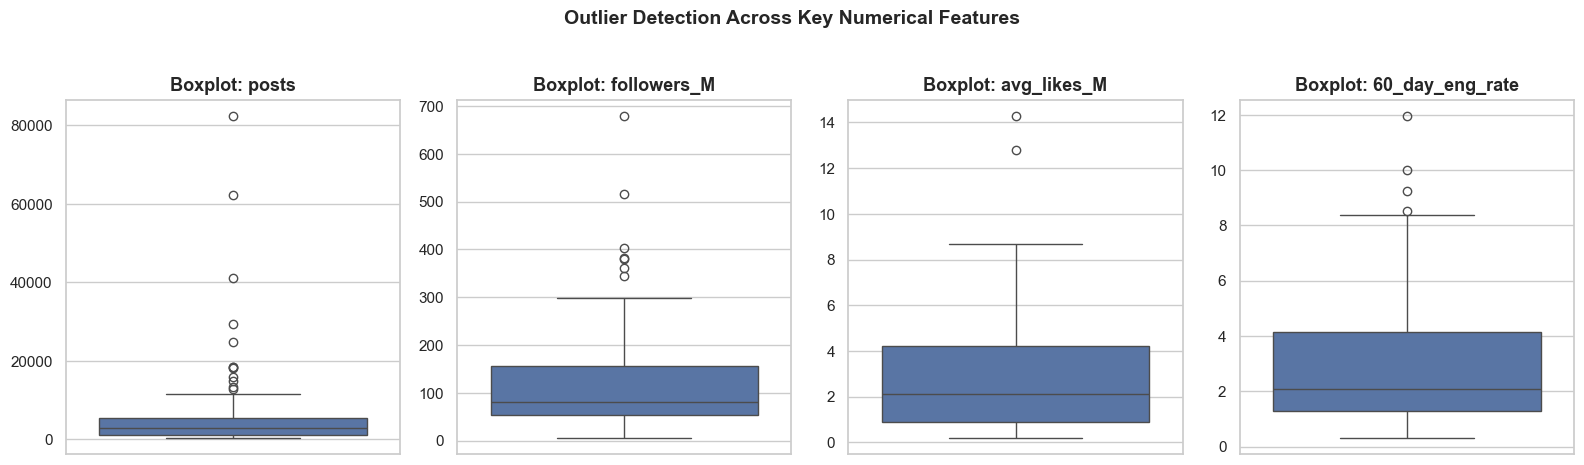

--- IQR Outlier Detection Summary ---
posts              | Upper Threshold: 11732.88 | Outliers: 12 | Notable: wwe, nba, snoopdogg, natgeo
followers_M        | Upper Threshold:   309.88 | Outliers:  7 | Notable: cristiano, leomessi, selenagomez, therock
avg_likes_M        | Upper Threshold:     9.18 | Outliers:  2 | Notable: leomessi, cristiano
60_day_eng_rate    | Upper Threshold:     8.50 | Outliers:  4 | Notable: postmalone, tomholland2013, harrystyles, badbunnypr


In [18]:
outlier_cols = ['posts', 'followers_M', 'avg_likes_M', '60_day_eng_rate']

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for i, col in enumerate(outlier_cols):
    sns.boxplot(y=df[col], ax=axes[i], color='#4c72b0')
    axes[i].set_title(f'Boxplot: {col}')
    axes[i].set_ylabel('')

plt.suptitle('Outlier Detection Across Key Numerical Features', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

# Programmatic IQR outlier summary
print("--- IQR Outlier Detection Summary ---")
for col in outlier_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[df[col] > upper_bound]
    top_names = ', '.join(outliers.sort_values(by=col, ascending=False)['channel_info'].head(4).tolist())
    print(f"{col:18s} | Upper Threshold: {upper_bound:8.2f} | Outliers: {len(outliers):2d} | Notable: {top_names}")

## 8. Key Findings & Conclusion

1. **Clean, Complete Dataset:** The dataset contains **100 global influencers** across **11 features** with **0 missing values** and **0 duplicate records**.
2. **Geographic Concentration:** The **United States** dominates the top 100 list (**47 accounts**), followed by **India (13)**, the **United Kingdom (9)**, and **South Korea (6)**.
3. **Category Dominance:** **Music** (including K-Pop and Music/Entertainment sub-genres) is the largest vertical, followed by **Sports**, **Entertainment**, and **Content Creators**.
4. **Reach vs. Engagement Trade-Off:**
   - `followers` correlates strongly and positively with `avg_likes` ($r = 0.72$) and `influence_score` ($r = 0.86$).
   - However, `followers` has a **negative correlation** with `60_day_eng_rate` ($r = -0.32$): mega-accounts (>300M followers) typically see 1%–3% engagement, whereas mid-to-upper tier accounts (especially K-Pop artists) achieve engagement rates exceeding **8%–11%**.
5. **Posting Volume vs. Per-Post Impact:** `posts` has virtually zero correlation with `followers` ($r = -0.04$) and a negative correlation with `avg_likes` ($r = -0.27$), showing that high posting frequency (e.g., news/sports media pages with 30,000–80,000+ posts) dilutes per-post engagement compared to selective personal celebrity accounts.
6. **Positive Recent Momentum:** Across nearly all top influencers, `new_post_avg_likes` exceeds historical `avg_likes` (mean ratio > 1.08), indicating strong ongoing audience growth in 2026.